In [1]:
import torch
import transformers
import sklearn
import pandas as pd
import numpy as np
import sys

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bert_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.10.11
PyTorch: 2.6.0+cu126
Transformers: 5.15.1
scikit-learn: 1.7.2
CUDA available: True
GPU: NVIDIA GeForce RTX 3070
VRAM: 8.0 GB


In [2]:
from pathlib import Path
import json
import os
import random
import gc
import warnings

import numpy as np
import pandas as pd
import torch

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    roc_auc_score,
    top_k_accuracy_score,
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
    set_seed,
)

warnings.filterwarnings("ignore")

# --------------------------------------------------
# PATHS
# --------------------------------------------------
BASE_DIR = Path(
    r"C:/Users/CH.SC.U4CSE23160/Neural Project/IndicHallbench-Hallucinations-Benchmark"
)

DATA_PATH = BASE_DIR / "data/annotations/final/final_annotations.csv"
RESPONSES_PATH = BASE_DIR / "data/annotations/working/responses.json"
REFERENCES_PATH = BASE_DIR / "data/annotations/working/references.json"
ADJUDICATED_PATH = BASE_DIR / "data/validation/adjudicated_annotations.csv"
OUTPUT_DIR = BASE_DIR / "results/xlmr_base_human_validation"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# MODEL & TRAINING HYPERPARAMETERS
# --------------------------------------------------
MODEL_NAME = "FacebookAI/xlm-roberta-base"
MAX_LENGTH = 256
TRAIN_BATCH_SIZE = 4
EVAL_BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 4
EPOCHS = 6                      # slightly more, early stopping will cut
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
MAX_GRAD_NORM = 1.0

SEED = 42

set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Determinism (may slow training slightly)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)
print("Model:", MODEL_NAME)
print("Output:", OUTPUT_DIR)

Device: cuda
Model: FacebookAI/xlm-roberta-base
Output: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\results\xlmr_base_human_validation


In [3]:
annotations = pd.read_csv(DATA_PATH)

def load_json_records(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    if isinstance(obj, dict):
        for key in ["data", "records", "responses", "references"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)
    raise ValueError(f"Unsupported JSON structure: {path}")


responses = load_json_records(RESPONSES_PATH)
references = load_json_records(REFERENCES_PATH)
adjudicated = pd.read_csv(ADJUDICATED_PATH)

print("Annotations:", annotations.shape)
print("Responses:", responses.shape)
print("References:", references.shape)
print("Adjudicated:", adjudicated.shape)

print("\nAnnotation columns:", annotations.columns.tolist())
print("\nResponse columns:", responses.columns.tolist())
print("\nReference columns:", references.columns.tolist())
print("\nAdjudicated columns:", adjudicated.columns.tolist())

Annotations: (64800, 20)
Responses: (64800, 10)
References: (10800, 11)
Adjudicated: (3600, 7)

Annotation columns: ['response_id', 'question_id', 'fact_id', 'language', 'model_name', 'timestamp', 'judge_model', 'annotation_timestamp', 'correctness_label', 'hallucination_types', 'severity', 'claims', 'reason', 'confidence', 'review_required', 'judge_prompt_tokens', 'judge_output_tokens', 'annotation_source', 'annotator_model', 'human_annotator']

Response columns: ['question_id', 'fact_id', 'domain', 'difficulty', 'fact_type', 'language', 'model_name', 'response', 'timestamp', 'source_url']

Reference columns: ['question_id', 'fact_id', 'domain', 'difficulty', 'question_type', 'question', 'ground_truth', 'answer_type', 'answer_length_category', 'primary_hallucination_type', 'source_url']

Adjudicated columns: ['response_id', 'final_correctness_label', 'final_hallucination_types', 'final_severity', 'final_evidence_support', 'adjudication_reason', 'adjudicator_id']


In [4]:
# 1. Required columns
required_response = ["question_id", "language", "model_name", "response"]
required_reference = ["question_id", "question", "ground_truth"]
required_annotation = ["response_id", "question_id", "language", "model_name"]
required_adjudicated = ["response_id", "final_correctness_label"]

for col in required_response:
    if col not in responses.columns:
        raise KeyError(f"Missing from responses.json: {col}")
for col in required_reference:
    if col not in references.columns:
        raise KeyError(f"Missing from references.json: {col}")
for col in required_annotation:
    if col not in annotations.columns:
        raise KeyError(f"Missing from final_annotations.csv: {col}")
for col in required_adjudicated:
    if col not in adjudicated.columns:
        raise KeyError(f"Missing from adjudicated_annotations.csv: {col}")

# 2. Normalize keys
KEYS = ["question_id", "language", "model_name"]

for df in [responses, annotations]:
    for col in KEYS:
        df[col] = df[col].astype("string").str.strip()

LANGUAGE_ALIASES = {"HIEN": "HI-EN", "HI_EN": "HI-EN", "HINGLISH": "HI-EN"}

for df in [responses, annotations]:
    df["language"] = df["language"].str.upper().replace(LANGUAGE_ALIASES)

# 3. Duplicate checks
if responses.duplicated(KEYS).any():
    raise ValueError("Duplicate KEYS in responses.json")
if annotations.duplicated(KEYS).any():
    raise ValueError("Duplicate KEYS in final_annotations.csv")

# 4. Attach response_id
annotation_keys = annotations[KEYS + ["response_id"]].copy()

responses_with_ids = responses.merge(
    annotation_keys, on=KEYS, how="left", validate="one_to_one", indicator=True
)

print("Response ID matching:")
print(responses_with_ids["_merge"].value_counts())

if (responses_with_ids["_merge"] != "both").any():
    raise ValueError("Some responses could not be matched to final_annotations.csv")

responses_with_ids.drop(columns="_merge", inplace=True)

# 5. Reference question_ids unique
if references["question_id"].duplicated().any():
    raise ValueError("Duplicate question_id in references.json")

# 6. Merge references
data = responses_with_ids.merge(
    references,
    on="question_id",
    how="left",
    validate="many_to_one",
    suffixes=("_response", "_reference"),
    indicator=True,
)

print("\nReference matching:")
print(data["_merge"].value_counts())

if (data["_merge"] != "both").any():
    raise ValueError("Some responses have no matching reference")

data.drop(columns="_merge", inplace=True)

# 7. Attach adjudicated labels
adjudicated["response_id"] = adjudicated["response_id"].astype("string").str.strip()
data["response_id"] = data["response_id"].astype("string").str.strip()

if adjudicated["response_id"].duplicated().any():
    raise ValueError("Duplicate response_id in adjudicated annotations")

data = data.merge(
    adjudicated[["response_id", "final_correctness_label"]],
    on="response_id",
    how="inner",
    validate="one_to_one",
)

# 8. Clean text
for col in ["question", "ground_truth", "response"]:
    data[col] = data[col].fillna("").astype(str).str.strip()

before = len(data)
data = data[
    (data["question"] != "") & (data["ground_truth"] != "") & (data["response"] != "")
].copy()
print("\nIncomplete text records removed:", before - len(data))

# 9. Validate labels
VALID_LABELS = ["Correct", "Partially Correct", "Incorrect", "Uncertain"]
data["final_correctness_label"] = data["final_correctness_label"].astype(str).str.strip()

invalid = sorted(set(data["final_correctness_label"]) - set(VALID_LABELS))
if invalid:
    raise ValueError(f"Unexpected labels: {invalid}")

# 10. Report
print("\n" + "=" * 55)
print("MERGED DATASET VALIDATION")
print("=" * 55)
print("Total usable records:", len(data))
print("Unique response IDs:", data["response_id"].nunique())
print("Unique questions:", data["question_id"].nunique())
print("Unique languages:", data["language"].nunique())
print("Unique models:", data["model_name"].nunique())

print("\nLanguage distribution:")
print(data["language"].value_counts())

print("\nModel distribution:")
print(data["model_name"].value_counts())

print("\nHuman correctness distribution:")
print(data["final_correctness_label"].value_counts())

Response ID matching:
_merge
both          64800
left_only         0
right_only        0
Name: count, dtype: int64

Reference matching:
_merge
both          64800
left_only         0
right_only        0
Name: count, dtype: int64

Incomplete text records removed: 0

MERGED DATASET VALIDATION
Total usable records: 3600
Unique response IDs: 3600
Unique questions: 600
Unique languages: 6
Unique models: 6

Language distribution:
language
EN       600
HI       600
HI-EN    600
NE       600
TA       600
TE       600
Name: count, dtype: Int64

Model distribution:
model_name
GPT-5.6 Luna           600
Claude Sonnet 5.5      600
DeepSeek-V4.1-Flash    600
Gemini 3               600
Qwen 3.7               600
GLM-5.3 Flash          600
Name: count, dtype: Int64

Human correctness distribution:
final_correctness_label
Correct              2803
Partially Correct     678
Incorrect             106
Uncertain              13
Name: count, dtype: int64


In [5]:
def build_input(row):
    # NOTE: Do NOT manually insert <s>/</s>; the tokenizer handles it.
    return (
        f"Question: {row['question']}\n"
        f"Ground Truth: {row['ground_truth']}\n"
        f"Model Response: {row['response']}"
    )

data["input_text"] = data.apply(build_input, axis=1)
data = data[data["input_text"].str.strip().ne("")].copy()

label_encoder = LabelEncoder()
data["label"] = label_encoder.fit_transform(data["final_correctness_label"])

LABELS = list(label_encoder.classes_)
NUM_LABELS = len(LABELS)

print("Label mapping:")
for i, label in enumerate(LABELS):
    print(f"  {i} = {label}")

print("\nFinal dataset shape:", data.shape)

Label mapping:
  0 = Correct
  1 = Incorrect
  2 = Partially Correct
  3 = Uncertain

Final dataset shape: (3600, 24)


In [6]:
if "fact_id" in data.columns:
    fact_ids = data["fact_id"].fillna("").astype(str).str.strip()
    data["split_group"] = np.where(
        (fact_ids != "") & (fact_ids.str.lower() != "nan"),
        "FACT_" + fact_ids,
        "QUESTION_" + data["question_id"].astype(str),
    )
else:
    data["split_group"] = "QUESTION_" + data["question_id"].astype(str)

print("Unique groups:", data["split_group"].nunique())

# TEST split (~15%)
sgkf_test = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
test_indices, remaining_indices = [], []
for fold, (train_idx, test_idx) in enumerate(
    sgkf_test.split(data["input_text"], data["label"], groups=data["split_group"])
):
    (test_indices if fold < 3 else remaining_indices).extend(test_idx)

# DEV split (~15% of remaining)
remaining = data.iloc[remaining_indices].copy()
sgkf_dev = StratifiedGroupKFold(n_splits=17, shuffle=True, random_state=SEED + 1)
dev_idx_local, train_idx_local = [], []
for fold, (tr, dv) in enumerate(
    sgkf_dev.split(remaining["input_text"], remaining["label"], groups=remaining["split_group"])
):
    (dev_idx_local if fold < 3 else train_idx_local).extend(dv)

train_df = remaining.iloc[train_idx_local].copy()
dev_df = remaining.iloc[dev_idx_local].copy()
test_df = data.iloc[test_indices].copy()

# Leakage checks
tr_g, dv_g, ts_g = (set(x["split_group"]) for x in [train_df, dev_df, test_df])
assert tr_g.isdisjoint(dv_g) and tr_g.isdisjoint(ts_g) and dv_g.isdisjoint(ts_g)

print(f"Train: {len(train_df)} | Dev: {len(dev_df)} | Test: {len(test_df)}")
print("Group leakage check: PASSED")

Unique groups: 600
Train: 2514 | Dev: 540 | Test: 546
Group leakage check: PASSED


split                Dev   Test  Train
label                                 
Correct            80.74  76.92  77.45
Incorrect           5.74   0.73   2.82
Partially Correct  13.52  22.34  19.21
Uncertain           0.00   0.00   0.52


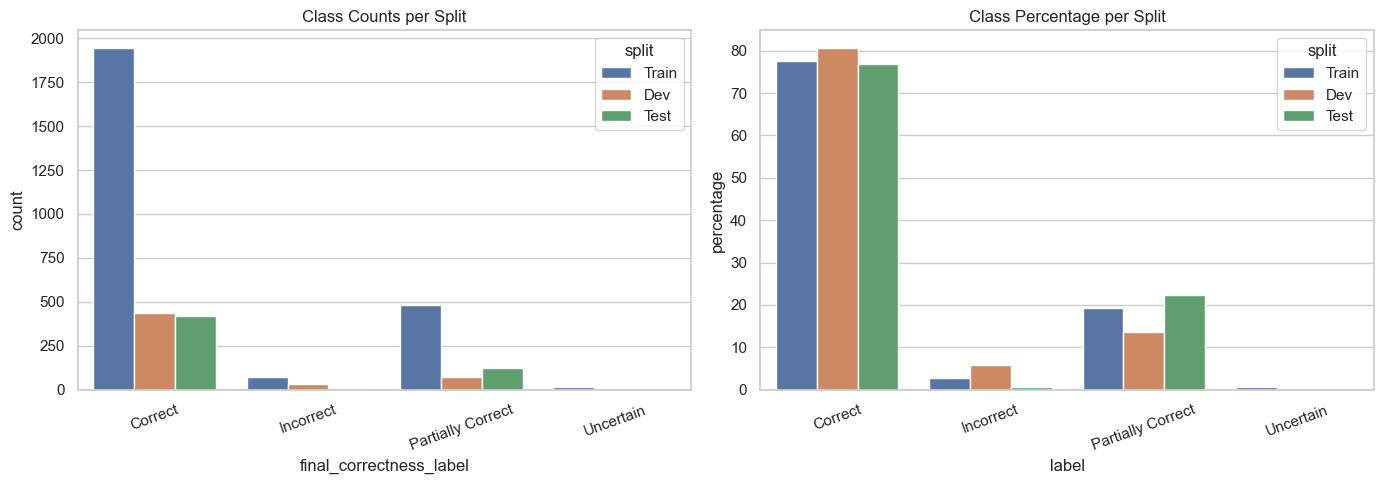

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

split_records = []
for name, part in [("Train", train_df), ("Dev", dev_df), ("Test", test_df)]:
    counts = part["final_correctness_label"].value_counts()
    for label in LABELS:
        c = counts.get(label, 0)
        split_records.append({
            "split": name, "label": label, "count": c,
            "percentage": c / len(part) * 100,
        })

split_dist = pd.DataFrame(split_records)

# Table
print(split_dist.pivot(index="label", columns="split", values="percentage").round(2))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=pd.concat([
        train_df.assign(split="Train"),
        dev_df.assign(split="Dev"),
        test_df.assign(split="Test"),
    ]),
    x="final_correctness_label", hue="split",
    order=LABELS, ax=axes[0],
)
axes[0].set_title("Class Counts per Split")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=split_dist, x="label", y="percentage", hue="split",
    order=LABELS, ax=axes[1],
)
axes[1].set_title("Class Percentage per Split")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "split_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

split_dist.to_csv(OUTPUT_DIR / "split_class_distribution.csv", index=False)

In [8]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class HallucinationDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.texts = df["input_text"].tolist()
        self.labels = df["label"].tolist()
        self.encodings = tokenizer(
            self.texts,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_tensors="pt",
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


train_dataset = HallucinationDataset(train_df)
dev_dataset = HallucinationDataset(dev_df)
test_dataset = HallucinationDataset(test_df)

print(f"Train: {len(train_dataset)} | Dev: {len(dev_dataset)} | Test: {len(test_dataset)}")

Train: 2514 | Dev: 540 | Test: 546


In [9]:
id2label = {i: label for i, label in enumerate(LABELS)}
label2id = {label: i for i, label in enumerate(LABELS)}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id,
)
model.to(DEVICE)
print("Model loaded.")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 2626.44it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded.


In [10]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    preds = np.argmax(logits, axis=-1)

    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(labels, preds, average="weighted", zero_division=0)
    acc = accuracy_score(labels, preds)

    # Extra robust metrics
    try:
        kappa = cohen_kappa_score(labels, preds)
    except Exception:
        kappa = float("nan")

    try:
        mcc = matthews_corrcoef(labels, preds)
    except Exception:
        mcc = float("nan")

    try:
        ll = log_loss(labels, probs, labels=list(range(NUM_LABELS)))
    except Exception:
        ll = float("nan")

    try:
        auc = roc_auc_score(
            labels, probs, multi_class="ovr", average="macro",
            labels=list(range(NUM_LABELS)),
        )
    except Exception:
        auc = float("nan")

    try:
        top2 = top_k_accuracy_score(labels, probs, k=min(2, NUM_LABELS),
                                    labels=list(range(NUM_LABELS)))
    except Exception:
        top2 = float("nan")

    return {
        "accuracy": acc,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "cohen_kappa": kappa,
        "mcc": mcc,
        "log_loss": ll,
        "roc_auc_macro": auc,
        "top2_accuracy": top2,
    }

In [11]:
# Compute total steps for warmup
steps_per_epoch = int(np.ceil(len(train_dataset) / (TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)))
total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

print(f"Steps/epoch: {steps_per_epoch} | Total: {total_steps} | Warmup: {warmup_steps}")

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "checkpoints"),
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=warmup_steps,          # FIX: was warmup_ratio
    max_grad_norm=MAX_GRAD_NORM,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    eval_strategy="epoch",              # FIX: was evaluation_strategy
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_strategy="steps",
    logging_steps=25,
    fp16=torch.cuda.is_available(),
    dataloader_num_workers=0,
    save_total_limit=2,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    processing_class=tokenizer,         # FIX: was tokenizer=
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

print("Trainer configured.")

Steps/epoch: 158 | Total: 948 | Warmup: 94
Trainer configured.


In [ ]:
print("Starting XLM-RoBERTa Base training...")
train_result = trainer.train()
print("\nTraining completed.")
print("Training metrics:", train_result.metrics)

trainer.save_model(OUTPUT_DIR / "best_model")
tokenizer.save_pretrained(OUTPUT_DIR / "best_model")
print("Best model saved.")

Starting XLM-RoBERTa Base training...


Epoch,Training Loss,Validation Loss


In [ ]:
history = trainer.state.log_history
train_loss = [(h["step"], h["loss"]) for h in history if "loss" in h and "epoch" in h]
eval_metrics = [(h["epoch"], h) for h in history if "eval_macro_f1" in h]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
if train_loss:
    s, l = zip(*train_loss)
    axes[0].plot(s, l, marker="o")
    axes[0].set_title("Training Loss")
    axes[0].set_xlabel("Step")
    axes[0].set_ylabel("Loss")

# Macro F1 / Accuracy
if eval_metrics:
    ep = [e for e, _ in eval_metrics]
    f1s = [m["eval_macro_f1"] for _, m in eval_metrics]
    accs = [m["eval_accuracy"] for _, m in eval_metrics]
    axes[1].plot(ep, f1s, marker="o", label="Macro F1")
    axes[1].plot(ep, accs, marker="s", label="Accuracy")
    axes[1].set_title("Dev Metrics")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    kappas = [m.get("eval_cohen_kappa", float("nan")) for _, m in eval_metrics]
    axes[2].plot(ep, kappas, marker="o", color="purple")
    axes[2].set_title("Dev Cohen's Kappa")
    axes[2].set_xlabel("Epoch")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:

# ============================================================
# TEST SET EVALUATION: COMPREHENSIVE CLASSIFICATION METRICS
# ============================================================

# 1. IMPORT LIBRARIES
import numpy as np
import torch
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    log_loss,
    top_k_accuracy_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# 2. GENERATE TEST PREDICTIONS
# ------------------------------------------------------------

test_results = trainer.predict(test_dataset)

test_logits = np.asarray(test_results.predictions)
test_true = np.asarray(test_results.label_ids)

# Extract logits if model returns a tuple
if isinstance(test_results.predictions, tuple):
    test_logits = np.asarray(test_results.predictions[0])

test_probs = torch.softmax(
    torch.as_tensor(test_logits, dtype=torch.float32),
    dim=-1
).cpu().numpy()

test_preds = np.argmax(test_logits, axis=1)

class_labels = list(range(NUM_LABELS))

# ------------------------------------------------------------
# 3. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST SET CLASSIFICATION REPORT")
print("=" * 70)

print(classification_report(
    test_true,
    test_preds,
    labels=class_labels,
    target_names=LABELS,
    digits=4,
    zero_division=0
))

# ------------------------------------------------------------
# 4. CLASSIFICATION METRICS
# ------------------------------------------------------------

# Accuracy
test_acc = accuracy_score(test_true, test_preds)

# Precision
test_macro_precision = precision_score(
    test_true, test_preds,
    average="macro",
    zero_division=0
)

test_weighted_precision = precision_score(
    test_true, test_preds,
    average="weighted",
    zero_division=0
)

# Recall
test_macro_recall = recall_score(
    test_true, test_preds,
    average="macro",
    zero_division=0
)

test_weighted_recall = recall_score(
    test_true, test_preds,
    average="weighted",
    zero_division=0
)

# F1-score
test_macro_f1 = f1_score(
    test_true, test_preds,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    test_true, test_preds,
    average="weighted",
    zero_division=0
)

# Balanced Accuracy
test_balanced_acc = balanced_accuracy_score(
    test_true, test_preds
)

# Agreement metrics
test_kappa = cohen_kappa_score(
    test_true, test_preds
)

test_mcc = matthews_corrcoef(
    test_true, test_preds
)

# ------------------------------------------------------------
# 5. ROC-AUC
# ------------------------------------------------------------

try:
    if NUM_LABELS == 2:
        test_auc = roc_auc_score(
            test_true,
            test_probs[:, 1]
        )
    else:
        test_auc = roc_auc_score(
            test_true,
            test_probs,
            multi_class="ovr",
            average="macro",
            labels=class_labels
        )
except ValueError as e:
    print("ROC-AUC warning:", e)
    test_auc = float("nan")

# ------------------------------------------------------------
# 6. LOG LOSS
# ------------------------------------------------------------

try:
    test_ll = log_loss(
        test_true,
        test_probs,
        labels=class_labels
    )
except ValueError as e:
    print("Log Loss warning:", e)
    test_ll = float("nan")

# ------------------------------------------------------------
# 7. TOP-2 ACCURACY
# ------------------------------------------------------------

try:
    test_top2 = top_k_accuracy_score(
        test_true,
        test_probs,
        k=min(2, NUM_LABELS),
        labels=class_labels
    )
except ValueError as e:
    print("Top-2 Accuracy warning:", e)
    test_top2 = float("nan")

# ------------------------------------------------------------
# 8. DISPLAY COMPLETE TEST RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL TEST SET PERFORMANCE")
print("=" * 70)

print(f"Accuracy:              {test_acc:.4f}")
print(f"Macro Precision:       {test_macro_precision:.4f}")
print(f"Weighted Precision:    {test_weighted_precision:.4f}")
print(f"Macro Recall:          {test_macro_recall:.4f}")
print(f"Weighted Recall:       {test_weighted_recall:.4f}")
print(f"Macro F1:              {test_macro_f1:.4f}")
print(f"Weighted F1:           {test_weighted_f1:.4f}")
print(f"Balanced Accuracy:     {test_balanced_acc:.4f}")
print(f"Cohen's Kappa:         {test_kappa:.4f}")
print(f"Matthews CC (MCC):     {test_mcc:.4f}")
print(f"ROC-AUC (Macro):       {test_auc:.4f}")
print(f"Log Loss:              {test_ll:.4f}")
print(f"Top-2 Accuracy:        {test_top2:.4f}")

# ------------------------------------------------------------
# 9. SAVE METRICS
# ------------------------------------------------------------

test_metrics_dict = {
    "Accuracy": test_acc,
    "Macro Precision": test_macro_precision,
    "Weighted Precision": test_weighted_precision,
    "Macro Recall": test_macro_recall,
    "Weighted Recall": test_weighted_recall,
    "Macro F1": test_macro_f1,
    "Weighted F1": test_weighted_f1,
    "Balanced Accuracy": test_balanced_acc,
    "Cohen's Kappa": test_kappa,
    "MCC": test_mcc,
    "ROC-AUC (Macro)": test_auc,
    "Log Loss": test_ll,
    "Top-2 Accuracy": test_top2
}

test_metrics_df = pd.DataFrame([test_metrics_dict])

display(test_metrics_df.round(4))

test_metrics_df.to_csv(
    "test_evaluation_metrics.csv",
    index=False
)

print("\nEvaluation completed successfully.")
print("Results saved: test_evaluation_metrics.csv")

In [ ]:
p, r, f, sup = precision_recall_fscore_support(
    test_true, test_preds, labels=list(range(NUM_LABELS)), zero_division=0
)

per_class = pd.DataFrame({
    "label": LABELS,
    "precision": p,
    "recall": r,
    "f1": f,
    "support": sup,
})
print(per_class.round(4))

# Plot per-class F1
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(per_class["label"], per_class["f1"], color="steelblue")
ax.axhline(test_macro_f1, color="red", linestyle="--", label=f"Macro F1 = {test_macro_f1:.3f}")
ax.set_ylim(0, 1)
ax.set_ylabel("F1 Score")
ax.set_title("Per-Class F1 (Test)")
ax.tick_params(axis="x", rotation=20)
for b, v in zip(bars, per_class["f1"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "per_class_f1.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
cm = confusion_matrix(test_true, test_preds, labels=list(range(NUM_LABELS)))
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
axes[0].set_title("Confusion Matrix (Counts)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens",
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[1])
axes[1].set_title("Confusion Matrix (Normalized)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix_raw_and_norm.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_true_bin = label_binarize(test_true, classes=list(range(NUM_LABELS)))

fig, ax = plt.subplots(figsize=(8, 6))
for i, label in enumerate(LABELS):
    if y_true_bin[:, i].sum() == 0:
        continue
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], test_probs[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{label} (AUC={roc_auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Per-Class ROC Curves (Test, One-vs-Rest)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Expected Calibration Error (ECE) — top-1 confidence
confidences = test_probs.max(axis=1)
correct = (test_preds == test_true).astype(int)

n_bins = 10
bin_edges = np.linspace(0, 1, n_bins + 1)
ece = 0.0
for i in range(n_bins):
    mask = (confidences >= bin_edges[i]) & (confidences < bin_edges[i + 1])
    if mask.sum() == 0:
        continue
    bin_conf = confidences[mask].mean()
    bin_acc = correct[mask].mean()
    ece += mask.sum() / len(confidences) * abs(bin_conf - bin_acc)

print(f"Expected Calibration Error (ECE): {ece:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Reliability diagram
bins_data = []
for i in range(n_bins):
    mask = (confidences >= bin_edges[i]) & (confidences < bin_edges[i + 1])
    if mask.sum() > 0:
        bins_data.append(((bin_edges[i] + bin_edges[i + 1]) / 2,
                         confidences[mask].mean(),
                         correct[mask].mean(),
                         mask.sum()))

if bins_data:
    xs, cs, acs, _ = zip(*bins_data)
    axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Perfect")
    axes[0].plot(cs, acs, "o-", label="Model")
    axes[0].set_xlabel("Mean Confidence")
    axes[0].set_ylabel("Accuracy")
    axes[0].set_title(f"Reliability Diagram (ECE={ece:.3f})")
    axes[0].legend()

# Confidence histogram by correctness
axes[1].hist(confidences[correct == 1], bins=20, alpha=0.6, label="Correct", color="green")
axes[1].hist(confidences[correct == 0], bins=20, alpha=0.6, label="Wrong", color="red")
axes[1].set_xlabel("Top-1 Confidence")
axes[1].set_ylabel("Count")
axes[1].set_title("Prediction Confidence Histogram")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "calibration.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
lang_records = []
for lang in sorted(test_df["language"].dropna().unique()):
    mask = test_df["language"].to_numpy() == lang
    yt, yp = test_true[mask], test_preds[mask]
    if len(yt) == 0:
        continue

    lang_records.append({
        "language": lang,
        "samples": int(mask.sum()),
        "accuracy": accuracy_score(yt, yp),
        "macro_f1": f1_score(yt, yp, labels=list(range(NUM_LABELS)),
                             average="macro", zero_division=0),
        "weighted_f1": f1_score(yt, yp, labels=list(range(NUM_LABELS)),
                                average="weighted", zero_division=0),
        "cohen_kappa": cohen_kappa_score(yt, yp),
    })

lang_results = pd.DataFrame(lang_records)
print(lang_results.round(4))
lang_results.to_csv(OUTPUT_DIR / "language_wise_results.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=lang_results, x="language", y="macro_f1", ax=axes[0], palette="viridis")
axes[0].set_title("Language-wise Macro F1")
axes[0].set_ylim(0, 1)
for i, v in enumerate(lang_results["macro_f1"]):
    axes[0].text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)

sns.barplot(data=lang_results, x="language", y="accuracy", ax=axes[1], palette="mako")
axes[1].set_title("Language-wise Accuracy")
axes[1].set_ylim(0, 1)

sns.barplot(data=lang_results, x="language", y="cohen_kappa", ax=axes[2], palette="flare")
axes[2].set_title("Language-wise Cohen's Kappa")
axes[2].axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "language_wise_results.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
model_records = []
for m in sorted(test_df["model_name"].dropna().unique()):
    mask = test_df["model_name"].to_numpy() == m
    yt, yp = test_true[mask], test_preds[mask]
    if len(yt) == 0:
        continue
    model_records.append({
        "model_name": m,
        "samples": int(mask.sum()),
        "accuracy": accuracy_score(yt, yp),
        "macro_f1": f1_score(yt, yp, labels=list(range(NUM_LABELS)),
                             average="macro", zero_division=0),
        "weighted_f1": f1_score(yt, yp, labels=list(range(NUM_LABELS)),
                                average="weighted", zero_division=0),
    })

model_results = pd.DataFrame(model_records)
print(model_results.round(4))
model_results.to_csv(OUTPUT_DIR / "model_wise_results.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=model_results, x="model_name", y="macro_f1", palette="crest", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("LLM Model-wise Macro F1 (Test)")
ax.tick_params(axis="x", rotation=20)
for i, v in enumerate(model_results["macro_f1"]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_wise_macro_f1.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
pred_df = test_df[[
    "response_id", "question_id", "language", "model_name",
    "final_correctness_label", "question", "ground_truth", "response",
]].copy()

pred_df["predicted_label"] = label_encoder.inverse_transform(test_preds)
pred_df["confidence"] = test_probs.max(axis=1)
pred_df["correct_prediction"] = (
    pred_df["final_correctness_label"] == pred_df["predicted_label"]
)

# Per-class probability columns
for i, label in enumerate(LABELS):
    pred_df[f"prob_{label}"] = test_probs[:, i]

pred_df.to_csv(OUTPUT_DIR / "test_predictions_full.csv", index=False)

# Errors only
errors = pred_df[~pred_df["correct_prediction"]]
errors.to_csv(OUTPUT_DIR / "test_errors.csv", index=False)
print(f"Total errors: {len(errors)} / {len(pred_df)}")

# High-confidence errors (most concerning)
high_conf_errors = errors.sort_values("confidence", ascending=False).head(50)
high_conf_errors.to_csv(OUTPUT_DIR / "high_confidence_errors.csv", index=False)

# Save metrics
metrics_output = {
    "model": MODEL_NAME,
    "task": "Four-class correctness classification",
    "train_rows": len(train_df),
    "dev_rows": len(dev_df),
    "test_rows": len(test_df),
    "labels": LABELS,
    "seed": SEED,
    "test_metrics": {
        "accuracy": float(test_acc),
        "macro_f1": float(test_macro_f1),
        "weighted_f1": float(test_weighted_f1),
        "cohen_kappa": float(test_kappa),
        "mcc": float(test_mcc),
        "roc_auc_macro": float(test_auc) if not np.isnan(test_auc) else None,
        "log_loss": float(test_ll) if not np.isnan(test_ll) else None,
        "top2_accuracy": float(test_top2) if not np.isnan(test_top2) else None,
        "ece": float(ece),
    },
    "per_class": per_class.to_dict(orient="records"),
}

with open(OUTPUT_DIR / "test_metrics_full.json", "w", encoding="utf-8") as f:
    json.dump(metrics_output, f, indent=4)

print("All artifacts saved to:", OUTPUT_DIR)

In [ ]:
train_df.to_csv(OUTPUT_DIR / "train_split.csv", index=False)
dev_df.to_csv(OUTPUT_DIR / "dev_split.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_split.csv", index=False)
print("Split files saved.")

In [ ]:
del model, trainer
gc.collect()
torch.cuda.empty_cache()
print("Memory freed.")